## Machine Learning: Modelo Supervisado No 2. El Modelo Logit

### Andrés Eduardo Rangel Jiménez


- Economista `(Universidad del Valle, Colombia)`

- MSc en Econometria `(Universidad Torcuato Di Tella, Argentina)`

- PhD en Dirección de Empresas `(Universidad de Valencia, España)`

#### Bases de datos utilizadas:

- `Social_Network_Ads.csv`
- `escalera.dta`

In [109]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import seaborn as sns
from sklearn.model_selection import  RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, RocCurveDisplay
import pickle
import warnings
warnings.filterwarnings("ignore")#, category=DeprecationWarning)
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc

In [ ]:
from google.colab import files

# Abrir ventana para seleccionar el archivo
uploaded = files.upload()

## Ejemplo 1. Modelando la probabilidad de comprar un producto

In [6]:
## Importación de la base
datos=pd.read_csv("Social_Network_Ads.csv")
datos.head(12)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
5,15728773,Male,27,58000,0
6,15598044,Female,27,84000,0
7,15694829,Female,32,150000,1
8,15600575,Male,25,33000,0
9,15727311,Female,35,65000,0


La anterior base de datos es suministradas por Kaggle. Kaggle es una plataforma en línea, propiedad de Google, que se utiliza para ciencia de datos y machine learning. El conjunto de datos es sobre anuncios en redes sociales que describe a los usuarios y si han comprado un producto (tablet) haciendo clic en los anuncios que se les mostraron. Purchased (nuestra variable dependiente $y$) toma dos valores: 1:si compra y 0 sino compra. El significado de las demas variables se deduce con solo ver las etiquetas de las variables.

In [448]:
# Mirando la dimension de la base de datos
datos.shape

(400, 5)

Teuemos 400 filas (observaciones o individuos) y 5 columnas (variables). Recordemos que python En Python (al igual que en muchos lenguajes de programación como Java, JavaScript, C y C++ entre otros), el conteo de índices comienza en 0.  (chiste flojo: Es como si Python tuviera una ligera obsesión con empezar a contar antes que nosotros…)

In [42]:
##Inspección simple
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB



Codifico la variable Gender utilizando un **diccionario** y luego la convierto la variable Gender de object a int64

In [8]:
# Limpieza básica y conversión segura
# Crear diccionario de mapeo
mapa = {'Male': 1, 'Female': 0}
datos['Gender'] = datos['Gender'].map(mapa)   # convierte Male/Female
#datos['Gender'] = datos['Gender'].fillna(0)   # reemplaza NaN por 0
datos['Gender'] = datos['Gender'].astype('int64')

In [10]:
valores_unicos = datos['Gender'].unique()
print(valores_unicos)

[1 0]


In [12]:
datos.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,1,19,19000,0
1,15810944,1,35,20000,0
2,15668575,0,26,43000,0
3,15603246,0,27,57000,0
4,15804002,1,19,76000,0


A continuación voy a seleccionar un subconjunto de variables de la base de datos. Para ello usando Pandas selecciono un subconjunto de columnas de un DataFrame llamado datos utilizando indexación por posición.

- .iloc → método de Pandas para seleccionar filas y columnas por su posición numérica (no por nombre).
- : → significa “todas las filas”.
- 2:4 → significa “desde la columna en posición 2 hasta la columna en posición 3” (el 4 no se incluye, porque el final en Python es exclusivo).

In [15]:
###Separemos la base entre covariables y etiqueta
x = datos.iloc[:,1:4]
y = datos.iloc[:,-1]

In [17]:
x.head()

,Gender,Age,EstimatedSalary
0,1,19,19000
1,1,35,20000
2,0,26,43000
3,0,27,57000
4,1,19,76000


In [19]:
y.head(12)

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     1
8     0
9     0
10    0
11    0
Name: Purchased, dtype: int64

In [21]:
y.value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

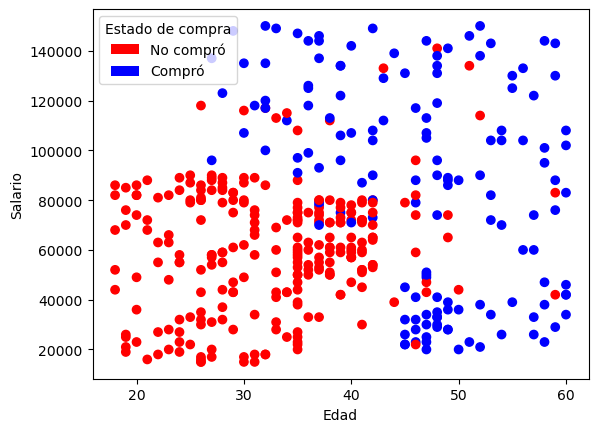

In [23]:
# Definir colores para 0 y 1
cmap = ListedColormap(['red', 'blue'])

# Dibujar el scatter con los colores definidos
plt.scatter(x['Age'], x['EstimatedSalary'], c=y, cmap=cmap)

# Etiquetas de ejes
plt.xlabel("Edad")
plt.ylabel("Salario")

# Crear leyenda personalizada
legend_elements = [
    Patch(facecolor='red', label='No compró'),
    Patch(facecolor='blue', label='Compró')
]
plt.legend(handles=legend_elements, title="Estado de compra")

# Mostrar gráfico
plt.show()

### Una descripción general de la regresión logística



Supongamos que desea predecir si hoy será un día soleado o no. Hay dos resultados posibles: "soleado" o "no soleado". La variable de resultado también se conoce como "variable objetivo" o "variable dependiente".

Si 1=soleado, 0= no soleado, Probabilidad que voy a modelar es: la probabilidad de que haga un día soleado
Si 1= no soleado 0=soleado: estaría modelando la probabilidad de que haga un día no soleado.

Hay muchas variables que podrían influir en el resultado, como "temperatura del día anterior", "presión del aire", etc. Las variables influyentes se conocen como características, variables independientes o predictores; todos estos términos significan lo mismo.

Las regresiones logísticas se utilizan en muchos otros ámbitos, por ejemplo, en:

- sector bancario: estimar la solvencia de un deudor en función de su perfil (ingresos, activos, pasivos, etc.),
- marketing: estimar la propensión de un cliente a comprar un producto o servicio en función de su perfil (edad, sexo, salario, compras anteriores, etc.),
- deportes: estimar la probabilidad de que un jugador gane contra otro jugador en función de las características de los dos oponentes,
- política: responder a la pregunta “¿Un ciudadano votaría por nuestro partido político en las próximas elecciones?”
etc.

Los problemas de clasificación son una categoría importante de problemas en analítica en los que la variable de respuesta toma un valor discreto. En los problemas de clasificación, el objetivo principal es predecir la clase (o probabilidad de clase) en función de los valores de las variables explicativas o predictores. Existen varias técnicas que se utilizan para resolver problemas de clasificación, como la regresión logística, los árboles de clasificación, el análisis discriminante, el vecino más cercano K, etc.

La regresión logística es una técnica estadística para encontrar la existencia de una relación entre una variable dependiente cualitativa (discreta) (variable de resultado o respuesta) y varias variables independientes (variables explicativas o predictores). La regresión logística es uno de los potentes algoritmos de aprendizaje supervisado para resolver problemas de clasificación. La regresión logística no devuelve directamente la clase de observaciones. Nos permite estimar la probabilidad (P) de pertenencia a la clase. La probabilidad oscilará entre 0 y 1. Necesitamos decidir la probabilidad umbral en la que la categoría cambia de una a otra. De forma predeterminada, este valor se establece en p = 0,5 en muchos programas. Nos centraremos en la regresión logística binaria en la que la variable de respuesta (Y) solo toma dos valores: 1 (resultado positivo) o 0 (resultado negativo). 

Formalizando el modelo: 

Existen otras formas algebraicamente equivalentes de escribir el modelo de regresión logística. La primera es:
$$
\text{(Odds)}=\frac{P(Y=1)}{1-P(Y=1)}=e^z\quad \text{(Ecuación 1)}
$$


$$
P(Y=1)=\frac{e^z}{1+e^z}\quad \text{(Ecuación 2)}
$$

Veamos la relacion entre las anteriores dos ecuaciones. Se despeja $P(Y=1)$multiplicando ambos lados por $1−P(Y=1)$ en la siguiente ecuacion:

$$\frac{P(Y=1)}{1 - P(Y=1)} = e^z$$

$$P(Y=1) = e^z \cdot (1 - P(Y=1))$$

$$P(Y=1) = e^z - e^z \cdot P(Y=1)$$

Se agrupan los términos con P(Y=1)

$$P(Y=1) + e^z \cdot P(Y=1) = e^z$$

$$P(Y=1)(1 + e^z) = e^z$$

$$\boxed{P(Y=1) = \frac{e^z}{1 + e^z}}$$

donde: 

$$
Z=\beta_0+\beta_1X_i+..+\beta_pX_p\quad \text{(Ecuación 3)}
$$

Uno de los objetivos de los problemas de clasificación es predecir la probabilidad de clase, es decir, la probabilidad de que una observación pertenezca a una clase determinada. La ecuación anterior proporciona la probabilidad de clase de una observación que pertenece a la clase etiquetada como 1 (es decir, P(Y=1)). La función logística producirá una curva en forma de S.


$$
\\\pi=P(Y=1)
$$

$$
odds=\\\frac{\pi}{1-\pi}=e^z\quad \text{(Ecuación 4)}
$$

Tomando logaritmos a Ecuación 4. llegamos a Ecuación 5:

$$
logit(odds(success))=log\left(\frac{\pi}{1-\pi}\right)=\beta_0+\beta_1X_i+..+\beta_pX_p\quad \text{(Ecuación 5)}
$$

Donde $\pi(0\leq\pi\leq1)$ es la probabilidad de que ocurra un evento (éxito=$P(Y=1)$ y se denota $\pi=P(success)$. Nosotros encontramos $\hat\beta_1...\hat\beta_k$ que se utilizan como estimaciones para $\beta_1...\beta_k$ usando el metodo de maxima verosimilitud. El objetivo del estimador es estimar los parámetros que maximizan la función de verosimilitud logarítmica. 

La Ecuación 4 establece que el logaritmo (natural) de las probabilidades es una función lineal de las variables X (y a menudo se denomina **logaritmo de probabilidades**). La ecuación 5 se conoce como función logit (unidad de probabilidad logística). Cada pendiente se interpreta como un cambio en el logaritmo de las probabilidades por una variación de la variable explicativa.


Los "odds" reflejan la probabilidad de que ocurra un evento. Odds — exitos vs fracasos

Se pueden considerar como la relación entre los “éxitos” y los “no éxitos”. Por ejemplo, si estás midiendo la probabilidad de que alguien compre un producto es de 0.70 luego los odds 0,70 / (1 - 0,70) = 2.33, o 2.33:1."Por cada persona que no compra, hay 2.33 que si compran"



## Modelo Logit

In [27]:
from IPython.display import HTML, display

with open("logit_didactico.html", "r", encoding="utf-8") as f:
    html_content = f.read()

display(HTML(html_content))

Estimamos un modelo logit mediante la libreria statsmodels, pues esta nos permite visualizar la salida de la regresionn y el calculo
de los efectos marginales.  Cuando nos interesa mas el poder explicativo del modelo utilizamos esta libreria.

In [30]:
# Variables independientes y dependiente
X = sm.add_constant(x)  # Agregar constante para el intercepto


In [58]:
# Ajustar modelo logit
logit_model = sm.Logit(y, X).fit()

# Ver resultados
print(logit_model.summary())
aic = logit_model.aic
bic = logit_model.bic
print("AIC:", aic)
print("BIC:", bic)

Optimization terminated successfully.
         Current function value: 0.346314
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:              Purchased   No. Observations:                  400
Model:                          Logit   Df Residuals:                      397
Method:                           MLE   Df Model:                            2
Date:                Sat, 25 Apr 2026   Pseudo R-squ.:                  0.4688
Time:                        14:33:09   Log-Likelihood:                -138.53
converged:                       True   LL-Null:                       -260.79
Covariance Type:            nonrobust   LLR p-value:                 7.995e-54
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -12.4340      1.300     -9.566      0.000     -14.982      -9.886
Age           

## Calculando los OR (Odds Ratio)

In [61]:
# Odds Ratios = e^coeficiente
OR = np.exp(logit_model.params)
CI = np.exp(logit_model.conf_int())

resultado = pd.DataFrame({
  'OR': OR,
  'IC_lower': CI[0],
  'IC_upper': CI[1],
  'p-valor': logit_model.pvalues
})
print(resultado)

                       OR      IC_lower  IC_upper       p-valor
const            0.000004  3.116065e-07  0.000051  1.109389e-21
Age              1.262999  1.200471e+00  1.328785  2.007792e-19
EstimatedSalary  1.000036  1.000025e+00  1.000047  3.774246e-11


El modelo logit no calcula directamente el estadistico F para realizar inferencia global. Lo calculamos mediante la siguiente instrucción:


In [64]:
print(logit_model.wald_test("Age = 0, EstimatedSalary = 0", scalar=True))

<Wald test (chi2): statistic=86.58173719893676, p-value=1.581301381853372e-19, df_denom=2>


## Calculo de efectos marginales

In [67]:
marginal_effects = logit_model.get_margeff()
print(marginal_effects.summary())

        Logit Marginal Effects       
Dep. Variable:              Purchased
Method:                          dydx
At:                           overall
                     dy/dx    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Age                 0.0259      0.001     18.804      0.000       0.023       0.029
EstimatedSalary  3.977e-06   4.56e-07      8.717      0.000    3.08e-06    4.87e-06


Interpretemos el coeficinete asociaso a edad:   Age=0.0262.  Por un incremento de un año de edad la probabilídad de que la persona haga la comprar se incrementa en 2.62%. EstimatedSalary=4.022e-06 (0.000004022).   Por un incremento de un dolar en el salario la probabilidad de comprar el producto aumenta en 0.0004%. Vemos que la variable no es significativa.  Sin embargo miremos la interpretacion: Si el comprador es hombre la probabilidad de comprar el articulo aumenta en 3.68% respecto a la mujer

## Saco la variable genero de la base de datos

In [71]:
###Separemos la base entre covariables y etiqueta
x = datos.iloc[:,2:4]
y = datos.iloc[:,-1]

In [73]:
x.head()

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


In [75]:
# Variables independientes y dependiente
X = sm.add_constant(x)  # Agregar constante para el intercepto
# Ajustar modelo logit
logit_model = sm.Logit(y, X).fit()
# Ver resultados
print(logit_model.summary())
aic = logit_model.aic
bic = logit_model.bic
print("AIC:", aic)
print("BIC:", bic)

Optimization terminated successfully.
         Current function value: 0.346314
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:              Purchased   No. Observations:                  400
Model:                          Logit   Df Residuals:                      397
Method:                           MLE   Df Model:                            2
Date:                Sat, 25 Apr 2026   Pseudo R-squ.:                  0.4688
Time:                        14:33:13   Log-Likelihood:                -138.53
converged:                       True   LL-Null:                       -260.79
Covariance Type:            nonrobust   LLR p-value:                 7.995e-54
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -12.4340      1.300     -9.566      0.000     -14.982      -9.886
Age           

El mejor modelo es el que excluye a la variable genero

## Usando el modelo para pronosticar 
```
Queremos predecir si un cliente comprará (1) o no (0) un producto según su edad y salario.

## Dividiendo los datos en train y test 

In [80]:
# Split the data into training and test sets
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state=42)

In [82]:
print(X_test.shape)
print(y_test.shape)

(80, 2)
(80,)


In [84]:
print(X_train.shape)
print(y_train.shape)

(320, 2)
(320,)


## Estimamos el modelo logistico con los datos de entrenamiento

In [87]:
modelo = LogisticRegression()
modelo.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## Pronosticamos usando con el modelo logistico con los datos de test (prueba)

In [90]:
y_pred=modelo.predict(X_test)

## Metricas de evaluacion para los modelos de clasificacion.


In [93]:
from IPython.display import IFrame

IFrame("Metricas_explicacion.html", width="100%", height=600)

## Metricas y matriz de confusión 

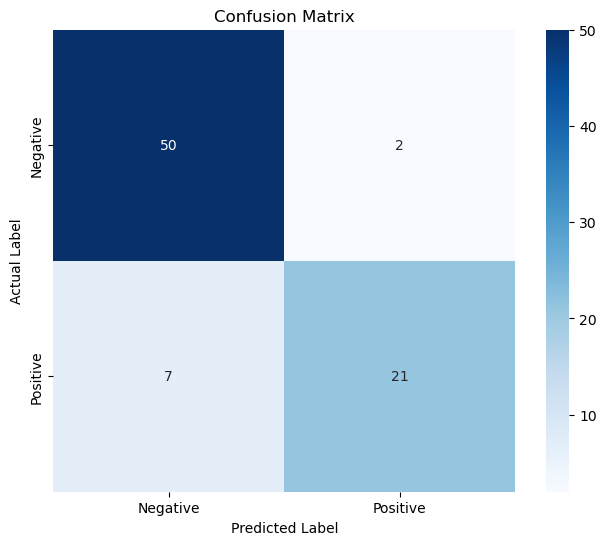

[[50  2]
 [ 7 21]]


In [96]:
cm=metrics.confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", square=True,
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix')
plt.show()
print(cm)

In [98]:
Para leer esta matriz tengase en cuenta que postive esta asociado al valor 1 en la variable dependiente dicotomica (1: compra el articulo) y negative esta asociado
al valor 0 (0: no compra el articulo)  en la variable dependiente dicotomica.

SyntaxError: invalid syntax (3120960593.py, line 1)

                 Predicho
                 |  0     |  1
         ________|________|________         
    real       0 | TN     | FP
       __________|________|__________
               1 | FN     | TP 

- TP (True Positives): predijo 1 y era 1
- TN (True Negatives): predijo 0 y era 0
- FP (False Positives): predijo 1 y era 0 (falso positivo)
- FN (False Negatives): predijo 0 y era 1 (falso negativo)

Se predijeron correctamente 50 negativos (no compra) y 19 positivos (si compra) Se cometieron 2 falsos positivos (predijo positivo (compra) pero era negativo (no compra). Se cometieron 9 falsos negativos (predijo negativos (no compra) pero eran positivos (compra)

In [101]:
##Evaluamos 
y_pred=modelo.predict(X_test)

error=(y_pred!=y_test).mean()*100

print(f"Predijimos un {error}% de datos en test incorrectamente")

Predijimos un 11.25% de datos en test incorrectamente


## Metricas de evaluacion para los modelos de clasificacion.

Para evaluar el clasificador KNN, también podemos utilizar el método de puntuación, pero ejecuta una métrica diferente, ya que estamos puntuando un clasificador y no un regresor. 

##### Precision:

La métrica básica para la clasificación es la precisión: describe cuántas predicciones acertó nuestro clasificador. El valor de precisión más bajo es 0 y el más alto es 1. Por lo general, multiplicamos ese valor por 100 para obtener un porcentaje.

$$
Accuracy=\frac{number\:\ of\:\ correct\:\  predictions}{total\:\ number\:\ of\:\ predictionsn}
$$

##### Recall: 

Para saber cuántos de los verdaderos positivos fueron identificados por nuestro clasificador. El recall se calcula dividiendo los verdaderos positivos por todo lo que debería haberse predicho como positivo.

$$
Recall = \frac{\text{true positive}}{\text{true positive} + \text{false negative}}
$$

##### F1 Score

Puntuación F1: es la media equilibrada o armónica de precisión y recall. El valor más bajo es 0 y el más alto es 1. Cuando la puntuación F1 es igual a 1, significa que se predijeron correctamente todas las clases;

$$
\text{f1-score} = 2* \frac{\text{precision} * \text{recall}}{\text{precision} + \text{recall}}
$$

In [103]:
##Accuracy
acc=metrics.accuracy_score(y_test,y_pred)
print("El accuracy score es " + str(acc))


##Recall
rec=metrics.recall_score(y_test,y_pred)
print("El recall score es " + str(rec))

##f1-score
f1=metrics.f1_score(y_test,y_pred)
print("El F1 score es " + str(f1))

El accuracy score es 0.8875
El recall score es 0.75
El F1 score es 0.8235294117647058


La precision del pronostico es de 88.75% (accuracy*100).  Esto nos dice que un 88.75% de los casos el modelo clasifica correctamente a los que compran el producto

Optimization terminated successfully.
         Current function value: 0.372821
         Iterations 7
AUC (test) = 0.9684


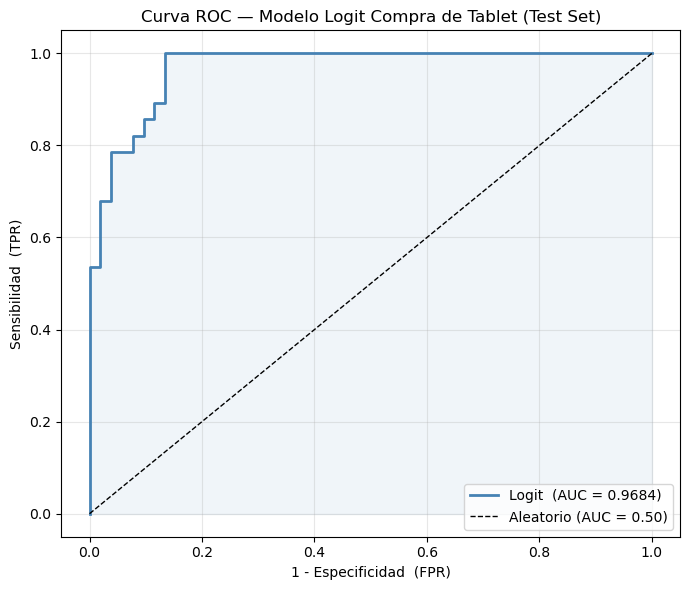

Umbral óptimo: 0.280  (Sens=1.000, Espec=0.865)

Tamaño test: 80 observaciones (28 compradores, 52 no compradores)


In [111]:
# ── 1. SPLIT ANTES DE ENTRENAR ─────────────────────────────
X = datos[['Age','EstimatedSalary']]
y = datos['Purchased']

X_train, X_test, y_train, y_test = train_test_split(       
    X, y, test_size=0.2, random_state=42                   
)                                                           

# ── 2. MODELO ENTRENADO SOLO CON TRAIN ─────────────────────
X_train_c = sm.add_constant(X_train)                        
modelo     = sm.Logit(y_train, X_train_c).fit()             

# ── 3. PROBABILIDADES SOBRE EL TEST ────────────────────────
X_test_c  = sm.add_constant(X_test, has_constant='add')    
y_prob    = modelo.predict(X_test_c)                        

# ── 4. ROC Y AUC ───────────────────────────────────────────
fpr, tpr, thresholds = roc_curve(y_test, y_prob)            
auc_score = auc(fpr, tpr)
print(f"AUC (test) = {auc_score:.4f}")

# ── 5. GRÁFICO ─────────────────────────────────────────────
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='steelblue', lw=2,
         label=f'Logit  (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatorio (AUC = 0.50)')
plt.fill_between(fpr, tpr, alpha=0.08, color='steelblue')
plt.xlabel('1 - Especificidad  (FPR)')
plt.ylabel('Sensibilidad  (TPR)')
plt.title('Curva ROC — Modelo Logit Compra de Tablet (Test Set)') 
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('curva_roc_test.png', dpi=150)                  
plt.show()

# ── 6. UMBRAL ÓPTIMO (Youden) ──────────────────────────────
idx_optimo = np.argmax(tpr - fpr)
umbral_opt = thresholds[idx_optimo]
print(f"Umbral óptimo: {umbral_opt:.3f}  "
      f"(Sens={tpr[idx_optimo]:.3f}, Espec={1-fpr[idx_optimo]:.3f})")

# ── 7. TAMAÑO DEL TEST (para referencia) ───────────────────
print(f"\nTamaño test: {len(y_test)} observaciones "        
      f"({y_test.sum()} compradores, "
      f"{(y_test==0).sum()} no compradores)")

## Ejemplo 2. Modelando la probabilidad de estar desempleado

In [ ]:
from google.colab import files

# Abrir ventana para seleccionar el archivo
uploaded = files.upload()

In [112]:
dtafile = 'escalera.dta'
df = pd.read_stata(dtafile,index_col='obs')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6700 entries, 1 to 7146
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   posicion     6699 non-null   float64
 1   genero       6699 non-null   float64
 2   desoc        4375 non-null   float64
 3   exper        6699 non-null   float64
 4   escolaridad  6667 non-null   float32
 5   ingnlab      6699 non-null   float64
 6   parti        6699 non-null   float64
 7   cp           6667 non-null   float32
 8   emp          4375 non-null   float32
 9   exper2       6699 non-null   float32
dtypes: float32(4), float64(6)
memory usage: 471.1+ KB


Esta base de datos corresponde al DANE, encuesta de hogares. El glosario de las variables que vamos a utilziar es el siguiente:

- posicion: 1: jefe de hogar, 0: no jefe
- genero: 1: hombre, 0:mujer
- desoc: 1: si esta desempleado, 0: empleado
- exper: años de experiecia laboral
- escolaridad:  años de educacion
- ingnlab: ingresos no laborales

In [115]:
df.head()

,posicion,genero,desoc,exper,escolaridad,ingnlab,parti,cp,emp,exper2
obs,,,,,,,,,,
1,1.0,1.0,0.0,53.0,4.0,35000.0,1.0,4.0,1.0,2809.0
2,0.0,0.0,NaN,51.0,0.0,0.0,0.0,0.0,NaN,2601.0
3,0.0,1.0,0.0,28.0,5.0,0.0,1.0,5.0,1.0,784.0
4,1.0,1.0,0.0,65.0,0.0,0.0,1.0,0.0,1.0,4225.0
5,1.0,0.0,0.0,57.0,0.0,0.0,1.0,0.0,1.0,3249.0


In [117]:
df = df.dropna()

In [119]:
dfX= df[["posicion", "genero", "exper", "escolaridad", "ingnlab" ]]
X, y = dfX, df.desoc

In [121]:
X.head()

,posicion,genero,exper,escolaridad,ingnlab
obs,,,,,
1,1.0,1.0,53.0,4.0,35000.0
3,0.0,1.0,28.0,5.0,0.0
4,1.0,1.0,65.0,0.0,0.0
5,1.0,0.0,57.0,0.0,0.0
6,0.0,0.0,26.0,7.0,0.0


In [123]:
X = sm.add_constant(X)  # Agregar constante para el intercepto

In [125]:
# Ajustar modelo logit
logit_model = sm.Logit(y, X).fit()

# Ver resultados
print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.454870
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                  desoc   No. Observations:                 4355
Model:                          Logit   Df Residuals:                     4349
Method:                           MLE   Df Model:                            5
Date:                Fri, 17 Apr 2026   Pseudo R-squ.:                 0.08750
Time:                        20:49:30   Log-Likelihood:                -1981.0
converged:                       True   LL-Null:                       -2170.9
Covariance Type:            nonrobust   LLR p-value:                 6.350e-80
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.8375      0.170      4.935      0.000       0.505       1.170
posicion       -0.6250    

Analicemos si los signos son los que esperamos segun la teoria:
- Si el individuo es jefe de hogar menor es su probabilídad de estar desempleado (respecto al no jefe)
- Si es hombre la probabilidad de estar desempleado es menor (respecto a la mujer)
- A mayor experiencia la probabilidad de estar desempleado es menor
- A mayor escolaridad la probabilidad de estar desempleado es menor
- A mayores ingresos no laborales la probabilidad de estar desempleado disminuye.

Son significativas estadisticamente cada variable de manera individual?

Calculando los efectos marginales.

In [130]:
marginal_effects = logit_model.get_margeff()
print(marginal_effects.summary())

        Logit Marginal Effects       
Dep. Variable:                  desoc
Method:                          dydx
At:                           overall
                 dy/dx    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
posicion       -0.0912      0.016     -5.742      0.000      -0.122      -0.060
genero         -0.0400      0.012     -3.269      0.001      -0.064      -0.016
exper          -0.0074      0.001    -12.523      0.000      -0.009      -0.006
escolaridad    -0.0056      0.002     -3.649      0.000      -0.009      -0.003
ingnlab      1.502e-07   3.68e-08      4.082      0.000    7.81e-08    2.22e-07


- Si la persona es jefe de hogar disminuye la probabilidad de estar desempleado en un 9.12 (0.0912*100) respecto a un no jefe de familia
- El ser hombre disminuye la probabilidad de estasr desempleado en un 4% (0.04*100) respecto a una mujer
- Un año adicional de experiencia disminye la probabilidad de estar desempleado en un 0.74%
- Un año adicional de educación disminuye la probabilidad de estar desempleado en un 0.56%

Para interpretar el efecto marginal de INGNLAB, cambiare la escala a 100000 mil.

Por cada 100.000 pesos de aumental en el ingreso no laboral (0.0000001502*100000=0.01502), la probabilidad de estar desempleado disminuye en
1.5%

Para ver si las variables son significativas en su conjunto llevo a cabo un test de Wald

In [134]:
print(logit_model.wald_test("posicion = 0, genero = 0, exper=0, escolaridad=0, ingnlab=0", scalar=True))

<Wald test (chi2): statistic=300.5446692183857, p-value=7.648292037691875e-63, df_denom=5>


La hipotesis nula y la alterna sigue la misma forma que cuando hicimos inferencia estadistica global en el modelo de regresión.
En este caso la Ho se rechaza pues el nivel de probabilidad es menor a 0.05 (nivel de signficancia escogido)

Como nuestro interes es clasificar y evaluar el clasificador (en este caso el modelo logit) debemos hacer la particion en train y test de la muestra


#### Dividiendo los datos en train y test 

In [139]:
# Split the data into training and test sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state=42)

#### Estandarizo variables

In [142]:
# Scale the features using StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#### Estimamos el modelo logistico con los datos de entrenamiento

In [145]:
modelo = LogisticRegression()
modelo.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


#### Metricas y matriz de confusión 

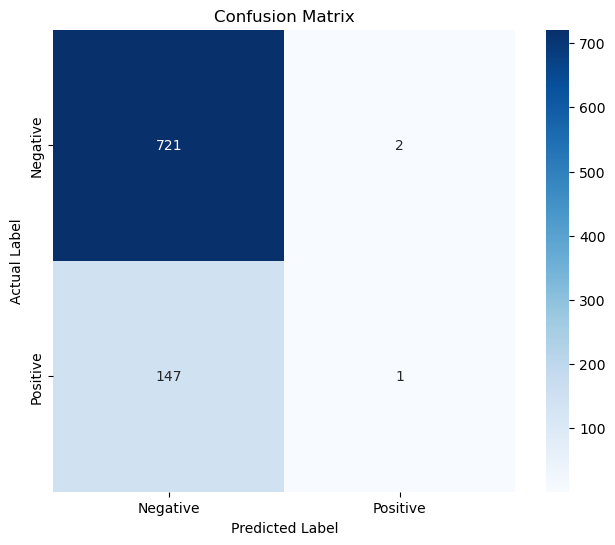

[[721   2]
 [147   1]]


In [148]:
##Matriz de confusión
y_pred=modelo.predict(X_test)

cm=metrics.confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", square=True,
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix')
plt.show()
print(cm)

Como desoc = 1 es “desempleado” y es la clase positiva:
- Positive = desempleado.
- Negative = empleado.

El modelo practicamente no encuentra positivos (desempleaados). Esto tiene que ver con el desbalance de la muestra: en la muestra may empleados que desempleados.

In [152]:
##Accuracy
acc=metrics.accuracy_score(y_test,y_pred)
print("El accuracy score es " + str(acc))


##Recall
rec=metrics.recall_score(y_test,y_pred)
print("El recall score es " + str(rec))

##f1-score
f1=metrics.f1_score(y_test,y_pred)
print("El F1 score es " + str(f1))

El accuracy score es 0.8289322617680827
El recall score es 0.006756756756756757
El F1 score es 0.013245033112582781


Un accuracy alto (0.829) pero recall y F1 prácticamente nulos,  casi siempre significa clase muy desbalanceada y que el modelo está prediciendo casi siempre la clase mayoritaria, por eso «acierta» muchas veces (accuracy) pero falla en detectar los positivos (recall) y por ende F1 es bajísimo. 

- Accuracy = 0.829: el modelo acierta ~82.9% de las predicciones, pero eso puede ser engañoso con desbalance.

- Recall = 0.0068 (~0.7%): de los casos positivos reales, solo detecta ~0.7%, esto es el modelo prácticamente no encuentra positivos.

- F1 = 0.0132: la armonía entre precision y recall es extremadamente baja, confirma el problema.

Conclusión: el modelo predice casi siempre la clase negativa

In [156]:
Hay desbalance?

Object `desbalance` not found.


In [158]:
y_test.value_counts()

desoc
0.0    723
1.0    148
Name: count, dtype: int64

Hay muchas mas personas empleadas en la muestra que desempleadas. Hay un desbalance.

Dataset equilibrado: 50%-50%
Moderado: 70%-30%
Severo: 90%-10%
Extremo: 99%-1%

(nota la cifra mas pequeña es la clase minoritaria)

En este caso: 

Clase 0= 723/871=83.0%
Clase 1= 148/871= 17.0%

Interpretación con la escala de arriba:
- Minoritaria (1.0) = 17% → desbalance moderado a severo.

No es un desbalance extremo (como 99%-1%), pero sí lo suficiente para que:
-Accuracy pueda ser engañoso.

- Valga la pena probar técnicas como class_weight='balanced', o rebalanceo con SMOTE.

In [162]:
Los negativos (0) son mayoria. 

SyntaxError: invalid syntax (2510061682.py, line 1)

In [164]:
Como solucionar este problema:

SyntaxError: invalid syntax (2288627129.py, line 1)

Tácticas:

1. Rebalanceo de la muestra:
- Oversampling: SMOTE, RandomOverSampler.
- Undersampling de la clase mayoritaria.

2. Penalizar la clase mayoritaria:
- Modelos con class_weight='balanced' o pesos personalizados.

3. Probar otros algoritmos (RandomForest, XGBoost) con ajuste de peso.

In [167]:
Probemos la opcion 2:

SyntaxError: invalid syntax (1808978278.py, line 1)

In [169]:
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train, y_train)

#En este caso (83% vs 17%), la clase 1 recibirá un peso mucho mayor, ayudando a que el modelo preste más atención a detectarla.

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


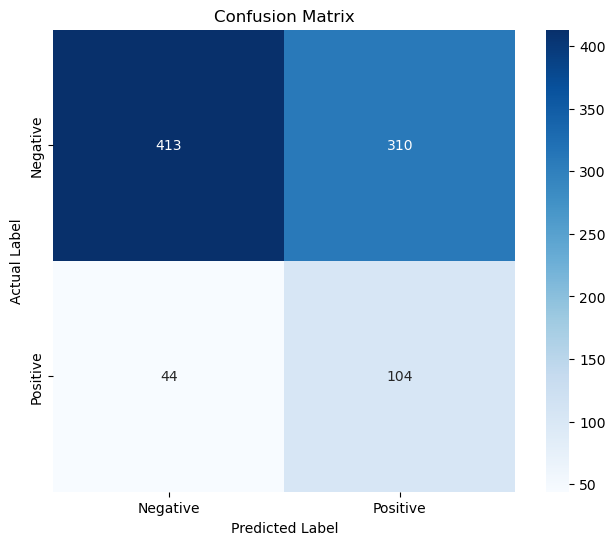

[[413 310]
 [ 44 104]]


In [171]:
##Matriz de confusión
y_pred=model.predict(X_test)

cm=metrics.confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", square=True,
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix')
plt.show()
print(cm)

In [173]:
##Accuracy
acc=metrics.accuracy_score(y_test,y_pred)
print("El accuracy score es " + str(acc))


##Recall
rec=metrics.recall_score(y_test,y_pred)
print("El recall score es " + str(rec))

##f1-score
f1=metrics.f1_score(y_test,y_pred)
print("El F1 score es " + str(f1))

El accuracy score es 0.5935706084959816
El recall score es 0.7027027027027027
El F1 score es 0.3701067615658363


Las metricas han mejorado al estimar el modelo con una muestra balanceada. Aunque el accuracy disminuyo las otras dos metricas nos muestran que el modelo
predice de manera adecuada ambas categorías: emmpleados y desempleados

La base de datos esta desbalanceada. Debe balancearse pues de lo contrario las metricas para evaluar los algoritmos no van a ser los mejores pues los modelos de
clasificación van a predecir con mayor probabilidad a la clase mayoritaria.

El accuracy es altísimo pero engañoso porque refleja la clase mayoritaria.

El modelo acierta casi siempre, pero solo porque predice “no fraude” para todo.
- Como el 99.87% de los datos son no fraudulentos, simplemente diciendo "todo es 0" ya alcanza esa exactitud.

Recall = 0.0

- El modelo no detecta ninguno de los fraudes.
- El recall mide la proporción de verdaderos positivos encontrados sobre todos los positivos reales:
$$
\text{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}}
$$


TP (True Positive)
Casos de fraude (1) que el modelo predijo correctamente como fraude.
- Ejemplo: había una transacción fraudulenta y el modelo dijo “fraude”.

FN (False Negative)
- Casos de fraude (1) que el modelo predijo como no fraude.
- Ejemplo: había una transacción fraudulenta pero el modelo dijo “no fraude”.
- Este es el error más costoso en este tipo de problemas, porque dejas pasar fraudes sin detectarlos.

En fraude, normalmente se busca maximizar Recall sin perder demasiado Precision.

##### Que se puede hacer?: 
- Rebalancear las clases con class_weight="balanced" en LogisticRegression.
- Técnicas de oversampling (ej. SMOTE) o undersampling.